# Animated Field Propagation in the Antiguide

This notebook introduces some of the animation capabilities of the slab package using the Antiguide as case study. 

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import slab2 as sg

from scipy.optimize import newton
from scipy.integrate import quad
from IPython.display import Video, HTML

plt.style.use('dark_background')
%matplotlib widget

In [2]:
A = sg.Slab(Ts=[4,2,4], ns=[1.44, 1, 1.44], wl=1e-6)


In [3]:
half_width = .5
shift = .25
amplitude = 1.

Lx = -half_width + shift
Rx = half_width + shift

def quadratic_piecewise(x):
    x = np.array(x, dtype=float)
    conds = [(x < Lx), ((Lx <= x)*(x <= Rx)), (x > Rx)]
    funcs = [lambda x: 0, lambda x: amplitude * (1 - ((x - shift) / half_width)**2), lambda x: 0]
    return np.piecewise(x, conds, funcs)
    
f0 = quadratic_piecewise

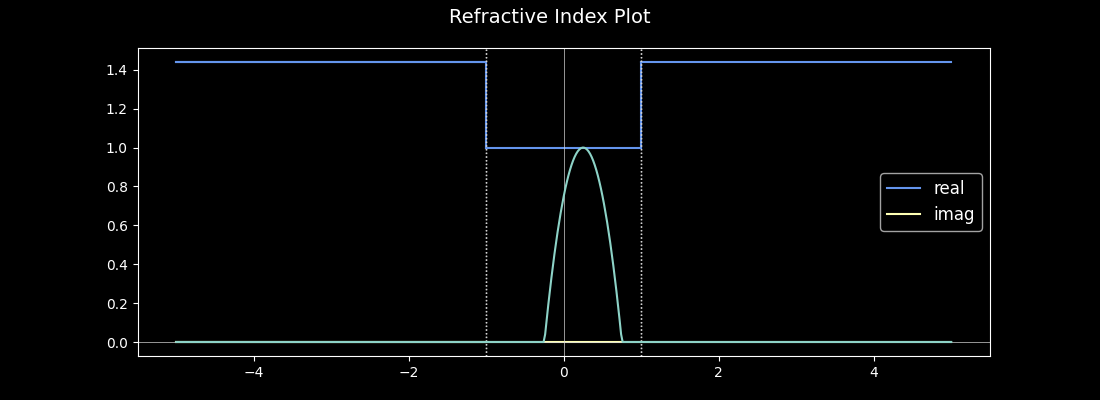

In [4]:
A.plot_refractive_index()
A.add_1d_plot(f0)

## Building the induced field

As in the Antiguide notebook, we determine the field induced by the input field using the Propagator Class:

In [9]:
P = sg.Propagator(A, f0=f0, window=[Lx,Rx])

In [10]:
P.add_contour(sg.real_contour(.00001, A.Z_evanescent.real, 300))

In [11]:
P.add_contour(sg.real_contour(6.5, 6.9, 200))

In [12]:
P.add_contour(sg.real_contour(A.Z_evanescent.real, 4*A.Z_evanescent.real, 300))

### Checking fields match at input

Before animating, we check that the calculated field matches the input field at the endface:

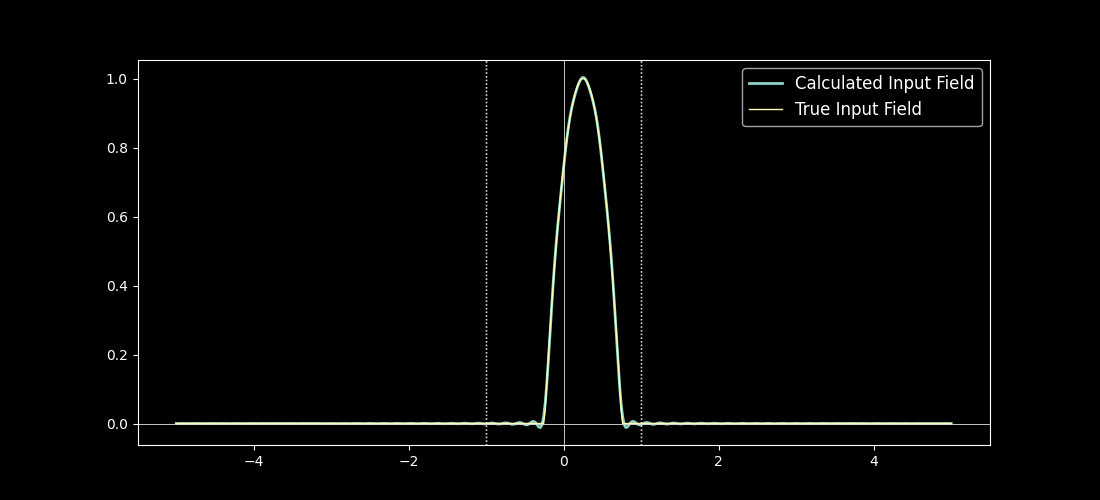

In [19]:
A.plot_field_1d(P, label='Calculated Input Field', lw=2);
A.add_1d_plot(f0, label='True Input Field', lw=1);

## Animating the induced field

We now can animate the birds eye view of the induced field we previously plotted only at time 0.  This requires using the routing animate_field_2d:

In [26]:
import os
video_path = 'animations/'

In [27]:
force_remake = False
file_path = video_path + "true_field_2d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d(A, P, file_path[:-4], zs=np.linspace(0, 12, 100), 
                    secs=2, fps=26, maxdim=6)

In [24]:
HTML("""
<div style="text-align: center;">
<video controls id="theVideo1"> <source src="animations/true_field_2d_animation.mp4"> </video>
<script> video1 = document.getElementById("theVideo1")
video2 = document.getElementById("theVideo2")
video1.width = 500; video1.playbackRate = 1; video1.loop = true; video1.autoplay = true;
</script>
</div>""")


## Leaky Modes

This pure radiation field should be well-approximated by the leaky field (unless the SDP contribution is also significant).

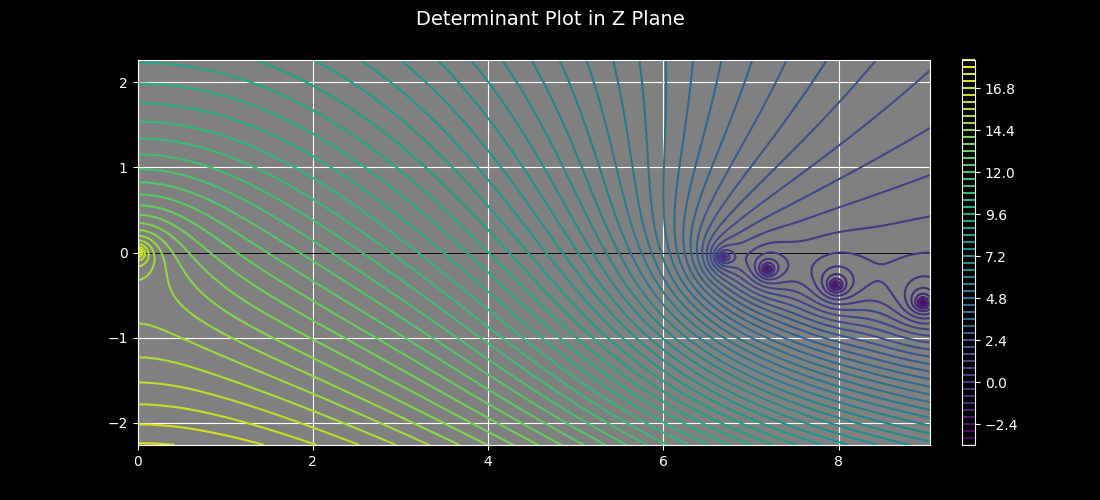

In [53]:
A.eigenvalue_plot(0, A.Z_evanescent, -.25*A.Z_evanescent,.25*A.Z_evanescent);


In [54]:
guesses = np.array([ 6.7 -.1j, 7.2 - .2j])
Zs_leaky = np.array([newton(A.eigenvalues, guess) for guess in guesses])
A.plot_points(Zs_leaky)

In [55]:
Fs_leaky = [A.fields(Z, rounding=11) for Z in Zs_leaky]
coeffs = np.array([quad(lambda x: f0(x) * F(x), Lx, Rx, complex_func=True)[0] for F in Fs_leaky])
Leaky = sg.Field(lambda x,z: sum([c * F(x,z) for c,F in zip(coeffs, Fs_leaky)]))

## Comparison of Leaky and True fields

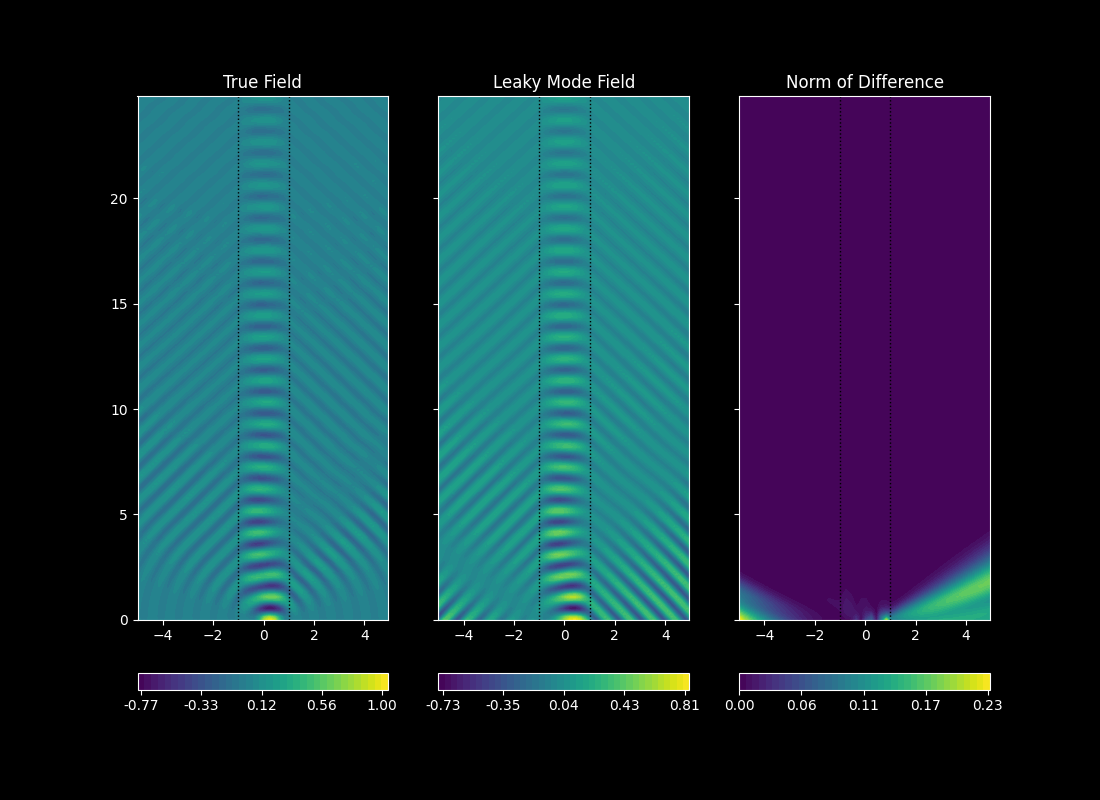

In [56]:
plt.close('all')
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, sharey=True, figsize=(11,8))

zmin = 0
zmax = 25
zref = int((zmax-zmin)*15/2)
zs = np.linspace(zmin, zmax, zref)

A.add_2d_plot(P, ax=ax1, zs=zs, colorbar=True);
ax1.set_title('True Field')

A.add_2d_plot(Leaky, ax=ax2, zs=zs, colorbar=True);
ax2.set_title('Leaky Mode Field')

A.add_2d_plot(abs(P.Full-Leaky)**2, ax=ax3, zs=zs, part='norm', colorbar=True);
ax3.set_title('Norm of Difference');

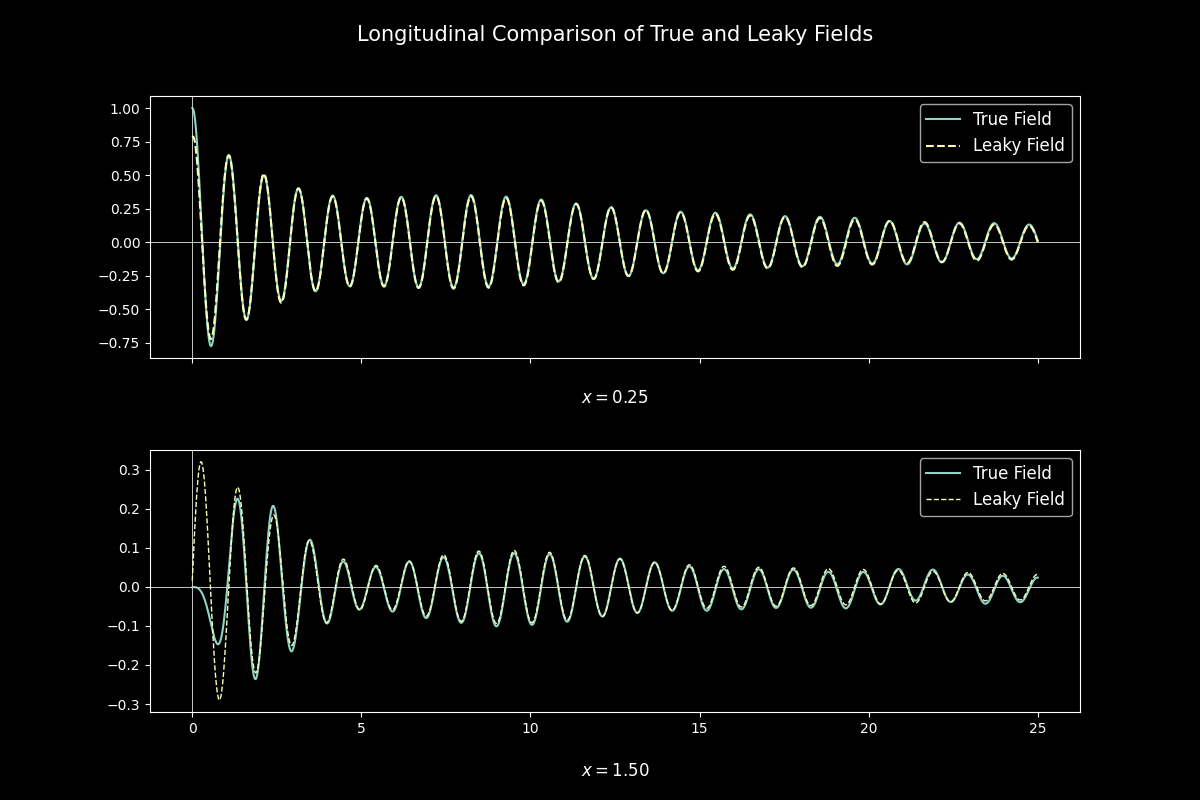

In [57]:
plt.close('all')
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(12,8), gridspec_kw = {'hspace':.35})

x1=shift
x2=1.5

zmin = 0
zmax = 25
zref = int((zmax-zmin)*80/2)
zs = np.linspace(zmin, zmax, zref)
ax1.set_title('Longitudinal Comparison of True and Leaky Fields\n\n', fontsize=15)

A.add_1d_plot(P, ax=ax1, xs=x1, zs=zs, label='True Field');
A.add_1d_plot(Leaky, ax=ax1, xs=x1, zs=zs, label='Leaky Field', ls='--');
# A.add_1d_plot(P.Full-Leaky, ax=ax1, xs=x1, zs=zs, label='Difference', lw=.75);
ax1.set_xlabel('\n$x=%.2f$'%x1, fontsize=12)


A.add_1d_plot(P, ax=ax2, xs=x2, zs=zs, label='True Field', lw=1.5);
A.add_1d_plot(Leaky, ax=ax2, xs=x2, zs=zs, label='Leaky Field', ls='--', lw=1);
# A.add_1d_plot(P.Full-Leaky, ax=ax2, xs=x2, zs=zs, label='Difference', lw=.75);
ax2.set_xlabel('\n$x=%.2f$'%x2, fontsize=12);

## Animations

### Transverse field at input

In [62]:
video_path = "animations/"

In [63]:
force_remake = False
file_path = video_path+"leaky.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_1d(A, Leaky, file_path='.mp4', linewidth=1.5, secs=2.5, fps=26, color='C0')

Video(file_path, html_attributes="controls loop")

#### Full field

In [75]:
force_remake = False
file_path = video_path + "leaky_field_2d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d(A, P, file_path[:-4], zs=np.linspace(0, 12, 100), 
                    secs=2, fps=26, maxdim=6)

In [76]:
HTML("""
<video controls id="theVideo1"> <source src="animations/true_field_2d_animation.mp4"> </video>
<video controls id="theVideo2"> <source src="animations/leaky_field_2d_animation.mp4"> </video>
<script> video1 = document.getElementById("theVideo1")
video2 = document.getElementById("theVideo2")
video1.width = 500; video1.playbackRate = 1; video1.loop = true; video1.autoplay = true;
video2.width = 500; video2.playbackRate = 1; video2.loop = true; video2.autoplay = true;
</script> """)


#### Animated surface plot

In [77]:
# Slow animation cell
force_remake = False
file_path = video_path + "true_field_3d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d_surface(A, P, file_path[:-4], fps=20, secs=2,
                               xs=np.linspace(-5,5,120), zmin=0, zmax=10, zref=200,
                               rstride=1, cstride=1, part='real',
                               azim=-47, elev=30, zoom=3.5, screen_dpi=120)

In [79]:
# Slow animation cell
force_remake = False
file_path = video_path + "leaky_field_3d_animation.mp4"

if not os.path.isfile(file_path) or force_remake:
    sg.animate_field_2d_surface(A, Leaky, file_path[:-4], fps=20, secs=2,
                               xs=np.linspace(-6,6,120), zmin=0, zmax=10, zref=200,
                               rstride=1, cstride=1, part='real',
                               azim=-47, elev=30, zoom=3.5, screen_dpi=120)

In [83]:
HTML("""
<div style="text-align: center;">
<video controls id="theVideo3"> <source src="animations/true_field_3d_animation.mp4"> </video>
<video controls id="theVideo4"> <source src="animations/leaky_field_3d_animation.mp4"> </video>
<script> video3 = document.getElementById("theVideo3")
video4 = document.getElementById("theVideo4")
video3.width = 700; video3.playbackRate = 1; video3.loop = true; video3.autoplay = true;
video4.width = 700; video4.playbackRate = 1; video4.loop = true; video4.autoplay = true;
</script> 
</div>""")

# Conclusion

Thanks for coming to the antiguide tutorial